# Demand-Profile Retrieval — PCA + k-NN (till PCA only)

Small end-to-end pipeline:

1. **Load** 10 demand profiles `df1..df10` (8760 hourly values each).
2. **Normalize** — separate *shape* from *magnitude* (we match on shape).
3. **PCA** — compress each 8760 shape into a few component scores.
4. **k-NN retrieval** — given a new profile `df11`, find the nearest stored profiles.

> `df1..df10` below are a **synthetic stand-in** so the notebook runs end to end. Replace that one cell with your real series. Everything downstream stays the same.

> Gappy POD is **not** here on purpose — it's only needed when the *new* profile is partial. A full `df11` just uses `pca.transform`.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors

HOURS = 8760          # one non-leap year of hourly demand
rng = np.random.default_rng(42)

## 1. Load profiles

**Replace this whole cell with your real `df1..df10`.** Each must be a length-8760 hourly demand series.

The stand-in builds three rough "families" (so retrieval has something meaningful to find) from diurnal + weekly + seasonal structure plus noise.

In [3]:
# ---- STAND-IN DATA: swap for your real df1..df10 ----
def _make_profile(base, daily_amp, weekly_drop, seasonal_amp, noise, phase=0):
    t = np.arange(HOURS)
    hour_of_day = t % 24
    day_of_week = (t // 24) % 7
    day_of_year = (t // 24)
    daily    = daily_amp * np.sin(2 * np.pi * (hour_of_day - 6 + phase) / 24)
    weekly   = np.where(day_of_week >= 5, -weekly_drop, 0.0)        # weekend dip
    seasonal = seasonal_amp * np.cos(2 * np.pi * day_of_year / 365)  # winter/summer
    series   = base + daily + weekly + seasonal + rng.normal(0, noise, HOURS)
    return pd.Series(np.clip(series, 0, None))

# family A (small, peaky)        family B (large, flat)        family C (tiny)      family D (medium, very peaky)
df1  = _make_profile(100, 40, 20, 30, 3,  0.0)
df2  = _make_profile(105, 42, 18, 28, 3,  0.3)
df3  = _make_profile( 98, 38, 22, 33, 3, -0.2)
df4  = _make_profile(300, 20, 50, 80, 8,  2.0)
df5  = _make_profile(310, 22, 55, 75, 8,  2.2)
df6  = _make_profile(295, 18, 48, 82, 8,  1.8)
df7  = _make_profile( 50, 10,  5, 10, 1,  4.0)
df8  = _make_profile( 52, 12,  6,  9, 1,  4.1)
df9  = _make_profile(180, 60, 30, 20, 5,  1.0)
df10 = _make_profile(175, 58, 28, 22, 5,  1.1)

## 2. Assemble into a matrix

Stack the 10 profiles into `X_raw` of shape `(10, 8760)` — one row per profile.

In [4]:
profiles = {f"df{i}": p for i, p in enumerate([df1, df2, df3, df4, df5, df6, df7, df8, df9, df10], start=1)}
labels   = list(profiles.keys())
X_raw    = np.vstack([profiles[k].to_numpy() for k in labels])
print("X_raw:", X_raw.shape)   # (10, 8760)

X_raw: (10, 8760)


## 3. Normalize — shape vs magnitude

We match profiles by **shape**, not size. Divide each row by its annual total so every row sums to 1 (pure shape). Keep `magnitude` separately — that's what you later re-scale by when estimating the new profile's actual values.

In [5]:
magnitude = X_raw.sum(axis=1, keepdims=True)   # annual energy per profile
X_shape   = X_raw / magnitude                  # each row sums to 1
print("row sums:", X_shape.sum(axis=1).round(6))

row sums: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


## 4. Fit PCA

PCA finds the dominant shape modes across the catalogue. The scree plot shows how many components `k` you actually need (PCA mean-centers internally, so we feed the normalized shapes directly).

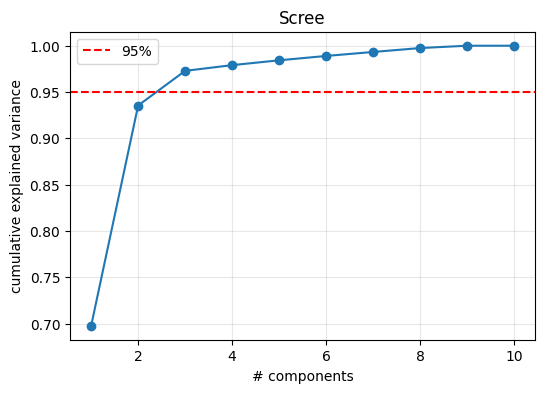

explained variance ratio: [0.698 0.238 0.037 0.006 0.005 0.005 0.004 0.004 0.003 0.   ]


In [6]:
pca_full = PCA().fit(X_shape)
evr = pca_full.explained_variance_ratio_

plt.figure(figsize=(6, 4))
plt.plot(np.arange(1, len(evr) + 1), np.cumsum(evr), marker="o")
plt.axhline(0.95, ls="--", c="r", label="95%")
plt.xlabel("# components"); plt.ylabel("cumulative explained variance")
plt.title("Scree"); plt.legend(); plt.grid(alpha=0.3); plt.show()

print("explained variance ratio:", evr.round(3))

In [7]:
# pick smallest k reaching 95% variance; clamp to a sane range (only 10 samples here)
k = int(np.searchsorted(np.cumsum(evr), 0.95) + 1)
k = max(2, min(k, len(labels) - 1))

pca    = PCA(n_components=k).fit(X_shape)
scores = pca.transform(X_shape)          # (10, k) — each profile as k numbers
print("k =", k, "| scores:", scores.shape)

k = 3 | scores: (10, 3)


## 5. Build the retrieval index (k-NN on scores)

We search in the low-dimensional **score space**, not the raw 8760. **Whiten** the scores (divide by each component's std) so the first component doesn't dominate the distance.

In [8]:
whiten   = np.sqrt(pca.explained_variance_)      # per-component scale
scores_w = scores / whiten

nn = NearestNeighbors(n_neighbors=3, metric="euclidean").fit(scores_w)
print("index built on", scores_w.shape[0], "profiles")

index built on 10 profiles


## 6. Retrieve neighbours for a new profile `df11`

Normalize the new profile the same way → project with `pca.transform` → whiten → k-NN. Returns the nearest stored profiles with distances.

In [9]:
def to_shape(profile):
    x = np.asarray(profile, dtype=float).reshape(1, -1)
    return x / x.sum(axis=1, keepdims=True)

def retrieve(new_profile, n=3):
    s = pca.transform(to_shape(new_profile)) / whiten
    dist, idx = nn.kneighbors(s, n_neighbors=n)
    return [(labels[i], round(float(d), 4)) for d, i in zip(dist[0], idx[0])]

In [10]:
# new demand — built close to the df4/df5/df6 family on purpose
df11 = _make_profile(305, 21, 52, 78, 8, 2.1)

print("nearest profiles to df11:")
for name, d in retrieve(df11, n=3):
    print(f"  {name:>4}  distance={d}")

nearest profiles to df11:
   df4  distance=0.1436
   df5  distance=0.2939
   df6  distance=0.3073


---

**What you have now:** fitted `pca`, the stored `scores`, and a `retrieve()` that returns the nearest profiles to any full new series. To turn a neighbour into an *estimate* for `df11`, take the neighbour's normalized shape and rescale by `df11`'s own magnitude (annual energy).

**Next step (not done here, as requested):** if `df11` arrives **partial** (missing hours), swap `pca.transform` for a masked least-squares projection onto `pca.components_` (Gappy POD) — same `scores`, same `retrieve()`, just computed from the observed hours.

<Axes: title={'center': 'df11 vs nearest neighbors'}>

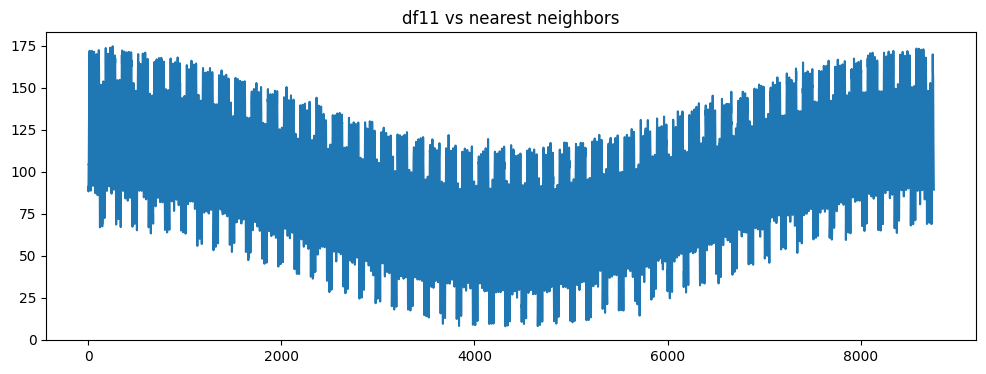

In [12]:
df1.plot(figsize=(12, 4), legend=False, title="df11 vs nearest neighbors")